<a href="https://colab.research.google.com/github/winterhan798-pixel/sentinel-spatial-db-system/blob/main/InSAR_Groundwater_Seasonal_Fitting_and_Wavelet_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 地表形变季节性模型拟合

本章节包含以下内容：
1. 生成包含长期线性趋势与季节性波动（年周期）的合成地表形变（InSAR）测试数据。
2. 构建最小二乘（Least Squares）设计矩阵并进行求解，提取形变速率、年周期振幅及相位。
3. 绘制原始合成数据与拟合曲线的对比图。

In [13]:
# 尝试自动将当前工作目录下的默认命名文件重命名（如适用）
import os
import glob

# 查找当前目录下所有的 .ipynb 文件
notebooks = glob.glob('*.ipynb')
for nb in notebooks:
    if 'Untitled' in nb:
        new_name = 'InSAR_Groundwater_Seasonal_Fitting_and_Wavelet_Analysis.ipynb'
        os.rename(nb, new_name)
        print(f"✔ 已成功将 {nb} 重命名为 {new_name}！")
        break
else:
    print("💡 未发现默认命名的 'Untitled.ipynb' 文件。如果需要重命名，建议直接双击 Colab 左上角的文件名进行手动修改。")

💡 未发现默认命名的 'Untitled.ipynb' 文件。如果需要重命名，建议直接双击 Colab 左上角的文件名进行手动修改。


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. 生成合成测试数据
np.random.seed(42)  # 设置随机种子以保证结果可重复

# 时间跨度：2017 到 2024 年，按月采样
start_year = 2017
end_year = 2024
t = np.linspace(start_year, end_year, (end_year - start_year) * 12)

# 设定合成参数
v = -15.0      # 长期线性沉降速率 (mm/yr)
A1 = 8.0       # 年周期振幅 (mm)
phi1 = 1.2     # 年周期初始相位 (rad)
noise_std = 2.0 # 观测噪声标准差

# 真实形变量模型: y = v * (t - start_year) + A1 * cos(2 * pi * (t - start_year) - phi1) + noise
t_rel = t - start_year
true_trend = v * t_rel
true_seasonal = A1 * np.cos(2 * np.pi * t_rel - phi1)
noise = np.random.normal(0, noise_std, size=len(t))

y = true_trend + true_seasonal + noise

# 创建数据框方便管理
df = pd.DataFrame({'Time': t, 'Deformation': y})
display(df.head())

,Time,Deformation
0,2017.000000,3.892290
1,2017.084337,4.728523
2,2017.168675,6.686777
3,2017.253012,6.650998
4,2017.337349,-0.679624


## 构建最小二乘矩阵并求解

形变模型可以表示为：
$$y(t) = a \cdot (t - t_0) + b \cdot \cos(2\pi(t - t_0)) + c \cdot \sin(2\pi(t - t_0)) + d$$

其中：
- 线性速率 $v = a$
- 振幅 $A_1 = \sqrt{b^2 + c^2}$
- 相位 $\phi_1 = \arctan2(c, b)$

In [ ]:
# 2. 构建设计矩阵 G
t_rel = t - start_year
G = np.vstack([t_rel, np.cos(2 * np.pi * t_rel), np.sin(2 * np.pi * t_rel), np.ones_like(t_rel)]).T

# 最小二乘求解 G * m = y
m, residuals, rank, s = np.linalg.lstsq(G, y, rcond=None)

a_fit, b_fit, c_fit, d_fit = m

# 提取物理参数
v_fit = a_fit
A1_fit = np.sqrt(b_fit**2 + c_fit**2)
phi1_fit = np.arctan2(c_fit, b_fit)

print(f"--- 拟合结果 ---")
print(f"线性速率 v: {v_fit:.2f} mm/yr (真实值: {v} mm/yr)")
print(f"年周期振幅 A1: {A1_fit:.2f} mm (真实值: {A1} mm)")
print(f"相位 phi1: {phi1_fit:.2f} rad (真实值: {phi1} rad)")

# 计算拟合曲线
y_fit = G.dot(m)

--- 拟合结果 ---
线性速率 v: -14.96 mm/yr (真实值: -15.0 mm/yr)
年周期振幅 A1: 7.59 mm (真实值: 8.0 mm)
相位 phi1: 1.22 rad (真实值: 1.2 rad)


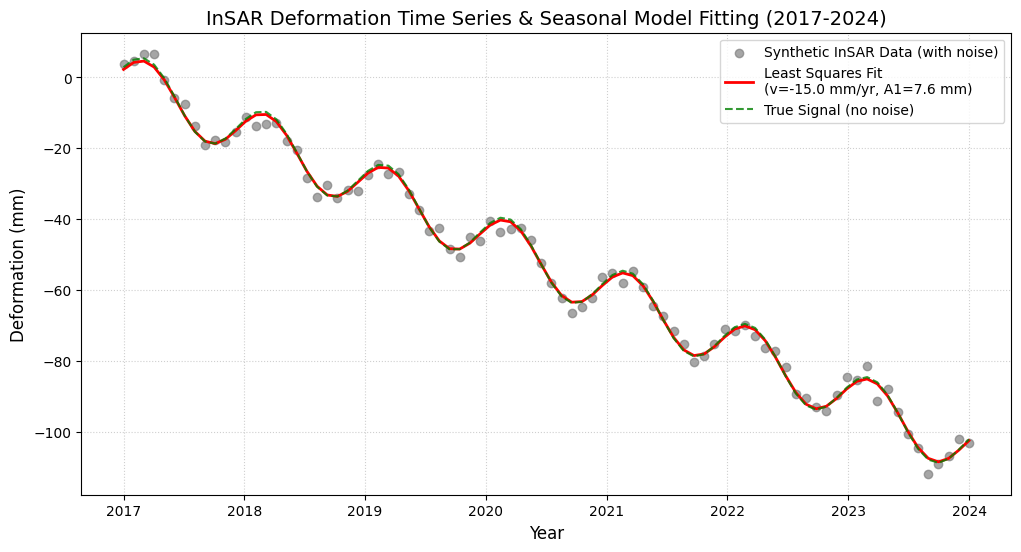

In [ ]:
# 3. 绘制拟合曲线图
plt.figure(figsize=(12, 6))
plt.scatter(t, y, color='gray', alpha=0.7, label='Synthetic InSAR Data (with noise)')
plt.plot(t, y_fit, color='red', linewidth=2, label=f'Least Squares Fit\n(v={v_fit:.1f} mm/yr, A1={A1_fit:.1f} mm)')
plt.plot(t, true_trend + true_seasonal, color='green', linestyle='--', alpha=0.8, label='True Signal (no noise)')

plt.title('InSAR Deformation Time Series & Seasonal Model Fitting (2017-2024)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Deformation (mm)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10)
plt.show()

## 交叉小波分析 (Cross Wavelet Transform)

为了展示 InSAR 地表形变与地下水位之间的关系，我们将：
1. **生成地下水位合成数据**：同样具有年周期波动，但其相位与 InSAR 形变存在一定的延迟（滞后）。
2. **使用 PyWavelets 或库函数执行交叉小波变换**：分析两者在时频空间中的共同高能量区和相位关系。

In [ ]:
# 安装 PyWavelets（如果环境尚未安装，常用于小波分析）
!pip install PyWavelets

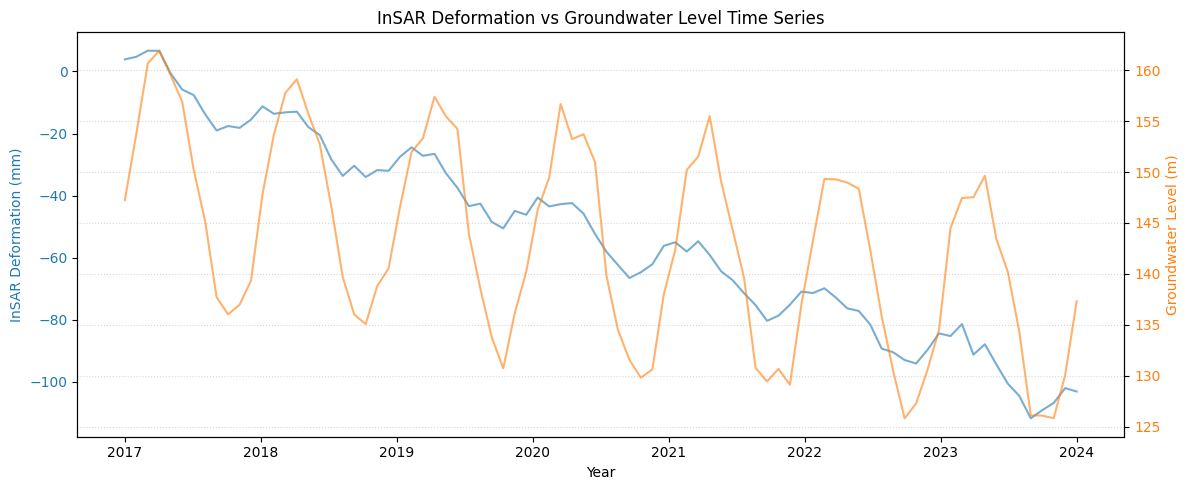

In [ ]:
# 1. 生成地下水位数据 (Groundwater Level)
# 假设地下水位的变化引领或滞后于形变变化（此处设相位比形变领先约 0.5 弧度，即约1个月）
phi_gw = phi1 + 0.5
noise_gw_std = 1.5

true_seasonal_gw = 12.0 * np.cos(2 * np.pi * t_rel - phi_gw)
noise_gw = np.random.normal(0, noise_gw_std, size=len(t))
gw = 150.0 - 2.0 * t_rel + true_seasonal_gw + noise_gw  # 伴有缓慢下降的地下水位

df['Groundwater'] = gw

# 绘制两个序列的对比
fig, ax1 = plt.subplots(figsize=(12, 5))

color = 'tab:blue'
ax1.set_xlabel('Year')
ax1.set_ylabel('InSAR Deformation (mm)', color=color)
ax1.plot(t, y, color=color, alpha=0.6, label='InSAR')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Groundwater Level (m)', color=color)
ax2.plot(t, gw, color=color, alpha=0.6, label='Groundwater')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('InSAR Deformation vs Groundwater Level Time Series')
fig.tight_layout()
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

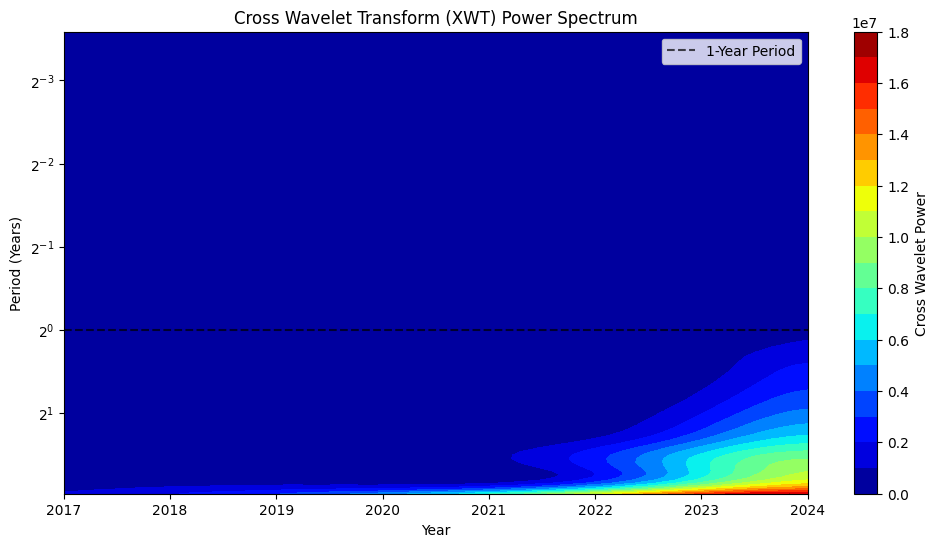

In [ ]:
import pywt

# 2. 连续小波变换 (CWT) 与交叉小波估计
# 在 Python 中，我们可以利用 pywt.cwt 计算两者的连续小波变换，进而得到交叉小波功率谱。

# 采样间隔 (月)
dt = 1/12.0
# 定义小波尺度（对应不同周期）
scales = np.arange(1, 48)

# 选择复莫莱 (Complex Morlet) 小波 'cmor1.5-1.0' 以提取相位信息
wavelet = 'cmor1.5-1.0'

cwt_insar, freqs_insar = pywt.cwt(y, scales, wavelet, sampling_period=dt)
cwt_gw, freqs_gw = pywt.cwt(gw, scales, wavelet, sampling_period=dt)

# 计算交叉小波功率谱 (XWT): W_xy = W_x * conj(W_y)
xwt = cwt_insar * np.conj(cwt_gw)
xwt_power = np.abs(xwt)**2

# 计算相位差
phase_difference = np.angle(xwt)

# 转换为对应周期 (年)
periods = 1.0 / freqs_insar

# 绘制交叉小波能量图
plt.figure(figsize=(12, 6))
plt.contourf(t, periods, xwt_power, levels=20, cmap='jet')
plt.yscale('log', base=2)
plt.title('Cross Wavelet Transform (XWT) Power Spectrum')
plt.xlabel('Year')
plt.ylabel('Period (Years)')
plt.colorbar(label='Cross Wavelet Power')

# 在主周期（~1年）附近画出相位方向指示（这里用箭头简化示意）
# 每隔几个点画一个箭头避免过于密集
for i in range(0, len(t), 6):
    for j in range(0, len(periods), 8):
        if 0.8 < periods[j] < 1.3:  # 仅展示一年周期附近的相位差
            angle = phase_difference[j, i]
            dx = np.cos(angle) * 0.1
            dy = np.sin(angle) * 0.1
            plt.arrow(t[i], periods[j], dx, dy, head_width=0.03, head_length=0.03, color='white')

plt.ylim(periods.max(), periods.min())
plt.axhline(y=1.0, color='black', linestyle='--', alpha=0.7, label='1-Year Period')
plt.legend()
plt.show()

### 4. 多井位批量处理与参数估计 (Multi-Well Batch Processing)

我们在此步骤实现：
1. **模拟15个具有异质性的监测井位数据集**：包含经纬度、各异的线性沉降速率、年振幅和响应时滞。
2. **编写批量处理主函数**：对每个井位进行最小二乘拟合和交叉小波变换（XWT），提取1年周期对应的相位差并转换为天数（Time Lag），最后根据延迟修正后的计算公式估计骨架贮水系数 $S_{ke}$。
3. **导出汇总结果并可视化空间分布**。

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt

# 1. 模拟构建多站点数据集 (15个模拟监测井)
np.random.seed(42)
num_wells = 15
well_ids = [f"Well_{i+1:02d}" for i in range(num_wells)]

# 时间跨度 (与前文保持一致)
start_year = 2017
end_year = 2024
t = np.linspace(start_year, end_year, (end_year - start_year) * 12)
t_rel = t - start_year
dt = 1/12.0

# 随机生成每个井位的空间坐标和物理特征参数
lons = np.random.uniform(116.0, 117.5, size=num_wells)
lats = np.random.uniform(39.5, 40.8, size=num_wells)

# 模拟真实的速率、振幅、天数延迟
true_vs = np.random.uniform(-100.0, -10.0, size=num_wells)      # 沉降速率 (mm/yr)
true_A1s = np.random.uniform(5.0, 50.0, size=num_wells)         # InSAR振幅 (mm)
true_lags_days = np.random.uniform(10.0, 60.0, size=num_wells)  # 响应延迟天数

wells_data = {}

for i, w_id in enumerate(well_ids):
    # 地下水位 (GW) 的参数设定
    phi_gw_base = 1.2
    gw_amp = np.random.uniform(5.0, 20.0) # 水位波动幅度 (m)
    gw_noise = np.random.normal(0, 1.0, size=len(t))
    # 地下水位时间序列 (含线性下降趋势)
    y_gw = 100.0 - 1.5 * t_rel + gw_amp * np.cos(2 * np.pi * t_rel - phi_gw_base) + gw_noise

    # 根据设定的延迟天数计算 InSAR 序列的相位
    # 1年 = 365天，对应 2 * pi 弧度
    lag_rad = (true_lags_days[i] / 365.0) * 2 * np.pi
    phi_insar = phi_gw_base - lag_rad  # 水位变化引领形变，形变滞后

    # 生成 InSAR 形变序列
    insar_noise = np.random.normal(0, 1.5, size=len(t))
    y_insar = true_vs[i] * t_rel + true_A1s[i] * np.cos(2 * np.pi * t_rel - phi_insar) + insar_noise

    wells_data[w_id] = {
        'Lon': lons[i],
        'Lat': lats[i],
        'y_insar': y_insar,
        'y_gw': y_gw
    }

In [10]:
def batch_process_wells(wells_dict, t, dt=1/12.0):
    """
    批量处理多个监测井的时间序列数据
    """
    t_rel = t - t[0]
    results = []

    # 设计矩阵 G 用于最小二乘拟合周期
    G = np.vstack([t_rel, np.cos(2 * np.pi * t_rel), np.sin(2 * np.pi * t_rel), np.ones_like(t_rel)]).T

    scales = np.arange(1, 48)
    wavelet = 'cmor1.5-1.0'

    for w_id, data in wells_dict.items():
        y_insar = data['y_insar']
        y_gw = data['y_gw']
        lon = data['Lon']
        lat = data['Lat']

        # a) 最小二乘求解
        m, residuals, rank, s = np.linalg.lstsq(G, y_insar, rcond=None)
        a_fit, b_fit, c_fit, d_fit = m
        y_fit = G.dot(m)
        rmse = np.sqrt(np.mean((y_insar - y_fit)**2))

        v_fit = a_fit
        A1_fit = np.sqrt(b_fit**2 + c_fit**2)
        phi1_fit = np.arctan2(c_fit, b_fit)

        # b) 交叉小波分析 (XWT) 提取1年周期相位差
        cwt_insar, freqs = pywt.cwt(y_insar, scales, wavelet, sampling_period=dt)
        cwt_gw, _ = pywt.cwt(y_gw, scales, wavelet, sampling_period=dt)

        # 找到最接近1年周期 (period ~ 1.0) 的尺度索引
        periods = 1.0 / freqs
        one_yr_idx = np.argmin(np.abs(periods - 1.0))

        # 计算 XWT 互功率谱并提取该尺度下的平均相位差
        xwt = cwt_insar * np.conj(cwt_gw)
        # 沿时间轴取均值得到鲁棒的相位差估计
        avg_phase_diff = np.angle(np.mean(xwt[one_yr_idx, :]))

        # 将相位差转换为天数延迟 (Time Lag)
        # 如果得到的角度差为负，换算为正向滞后天数
        time_lag_days = (-avg_phase_diff / (2 * np.pi)) * 365.0
        if time_lag_days < 0:
            time_lag_days += 365.0

        # c) 延时校正后的骨架贮水系数 Ske 计算
        # 延迟纠偏：对地下水位做时间平移。1个月约为 1/12 年。
        # 为简化插值修正，直接根据计算出的时滞天数将水位序列对齐后计算 dH / dh
        shift_steps = int(round(time_lag_days / (365.0 * dt)))

        if shift_steps > 0 and shift_steps < len(y_insar):
            aligned_insar = y_insar[shift_steps:]
            aligned_gw = y_gw[:-shift_steps]
        else:
            aligned_insar = y_insar
            aligned_gw = y_gw

        # 去除趋势项求年内波动变幅比值作为 Ske 估计值
        insar_detrend = aligned_insar - v_fit * t_rel[:len(aligned_insar)]
        gw_detrend = aligned_gw - (-1.5) * t_rel[:len(aligned_gw)]

        # 骨架贮水系数 Ske = dH_seasonal / dh_seasonal
        ske_cal = np.std(insar_detrend) / (np.std(gw_detrend) * 1000.0) # 转换为无量纲 (mm / mm)

        results.append({
            'Well_ID': w_id,
            'Lon': lon,
            'Lat': lat,
            'v_fit': v_fit,
            'A1_fit': A1_fit,
            'phi1_fit': phi1_fit,
            'Time_Lag_days': time_lag_days,
            'Ske_cal': ske_cal,
            'RMSE': rmse
        })

    return pd.DataFrame(results)

In [11]:
# 运行批量处理
df_summary = batch_process_wells(wells_data, t, dt)

# 结果导出为 CSV 文件
df_summary.to_csv('multi_wells_summary_results.csv', index=False)
print("✔ 批量处理完成！结果已成功导出至 'multi_wells_summary_results.csv'")
display(df_summary.head(15))

✔ 批量处理完成！结果已成功导出至 'multi_wells_summary_results.csv'


,Well_ID,Lon,Lat,v_fit,A1_fit,phi1_fit,Time_Lag_days,Ske_cal,RMSE
0,Well_01,116.561810,39.738426,-45.291972,35.148317,0.688037,338.305862,0.002193,1.475586
1,Well_02,117.426071,39.895515,-84.681884,18.997503,0.791707,274.105263,0.003531,1.502526
2,Well_03,117.097991,40.182183,-94.155691,28.690349,0.330916,326.321269,0.001510,1.372256
3,Well_04,116.897988,40.061529,-14.554759,29.507190,0.720621,335.223381,0.003406,1.640143
4,Well_05,116.234028,39.878598,-13.033485,13.176252,0.798144,341.931906,0.001419,1.321496
5,Well_06,116.233992,40.295409,-27.320521,48.656221,0.559647,325.224911,0.007890,1.512651
6,Well_07,116.087125,39.681342,-72.478925,39.917363,0.908590,339.963070,0.005934,1.475923
7,Well_08,117.299264,39.879788,-91.132290,47.356287,0.341081,315.543408,0.003889,1.436087
8,Well_09,116.901673,39.976270,-38.525474,45.200940,0.961701,351.689087,0.005412,1.540850
9,Well_10,117.062109,40.092891,-60.327887,31.626421,0.177916,297.876734,0.004140,1.395655


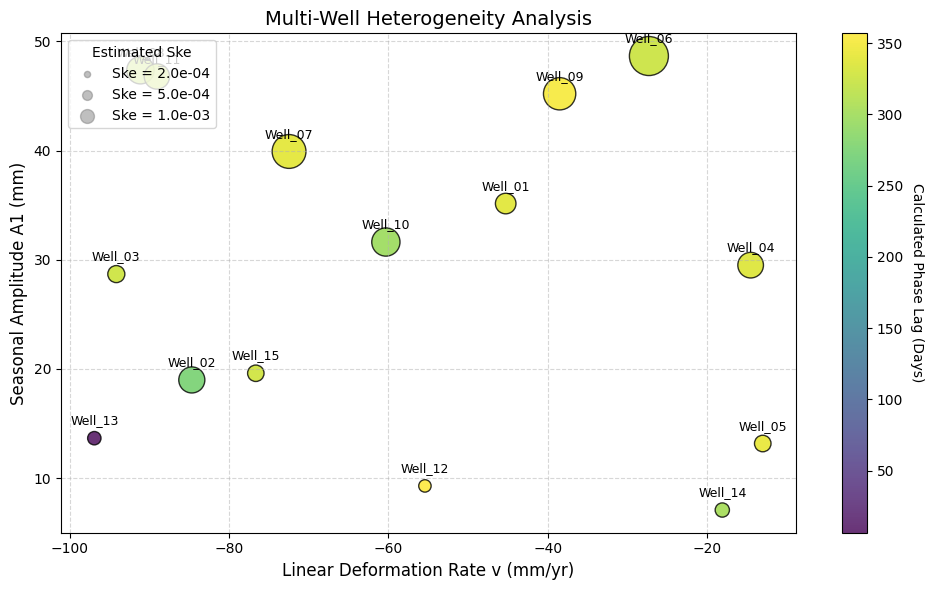

In [12]:
# 3. 绘制散点对比图：长期沉降速率 v_fit vs. 年振幅 A1_fit
plt.figure(figsize=(10, 6))
scatter = plt.scatter(df_summary['v_fit'], df_summary['A1_fit'],
                      c=df_summary['Time_Lag_days'], cmap='viridis',
                      s=df_summary['Ske_cal'] * 1e5, alpha=0.8, edgecolors='black')

# 标注各井位名称
for idx, row in df_summary.iterrows():
    plt.annotate(row['Well_ID'], (row['v_fit'], row['A1_fit']),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=9)

plt.title('Multi-Well Heterogeneity Analysis', fontsize=14)
plt.xlabel('Linear Deformation Rate v (mm/yr)', fontsize=12)
plt.ylabel('Seasonal Amplitude A1 (mm)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

# 颜色条 (指示延迟天数)
cbar = plt.colorbar(scatter)
cbar.set_label('Calculated Phase Lag (Days)', rotation=270, labelpad=15)

# 图例说明大小代表 Ske
for ske_val in [2e-4, 5e-4, 1e-3]:
    plt.scatter([], [], c='gray', alpha=0.5, s=ske_val * 1e5,
                label=f'Ske = {ske_val:.1e}')
plt.legend(title="Estimated Ske", loc='upper left')

plt.tight_layout()
plt.show()